# 006 - Stage 5 pilot: one inverse decoder per model

**Goal:** test whether an inverse decoder fine-tuned on one VAR model (var24) inverts that model's images better, and separates them from the other VAR depths, compared with the shared VAR inverse trained on all four depths (Zhao et al., App. V.1).

**Hypothesis:** a per-model inverse learns generation patterns specific to var24's transformer, so var24 images are inverted more accurately than by the shared inverse, and better than images from other depths.

**Inverses:** "E" (original encoder), "shared" (stage2/inv/var/final.pt), "single5" (var24 only, 5 epochs, primary), "single20" (var24 only, 20 epochs, step-matched, secondary).

**Pre-registered criteria** (fixed before results; evaluated on single5; pass uses point estimates, 95% CIs reported alongside):
- **C1 inversion:** on var24's holdout (512 images), single5 has >= 10% lower mean inv_mse than shared (1 - mean_single5 / mean_shared >= 0.10), OR >= 3 percentage points higher mean tok_recovery than shared.
- **C2 separation:** AUC of var24 vs var20 AND of var24 vs var30, using cal as the score (lower cal = more likely var24, i.e. score = -cal), under single5 is >= 0.75 for both pairs, and >= the same AUC under shared + 0.10 for both pairs.

single20 is reported with the same metrics as a secondary result; it does not change pass/fail.

"singlefull" (var24 only: the 2,560 stage2/gen images plus 7,680 new ones generated with seed 10, of which 9,840 are trained on, 5 epochs; added after the criteria were fixed) is reported as exploratory; it does not change pass/fail either.

In [1]:
# Setup and data: scores of the VAR generated holdout under each inverse (scripts/run_stage5_pilot.sh).
# CPU only; reads cached outputs, loads no model.
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata

REPO = Path("/workspace/iar-model-tracer")
S5 = Path("/workspace/cache/stage5")
OUT = REPO / "results" / "stage5"  # small tables and figures, committed
OUT.mkdir(parents=True, exist_ok=True)

DEPTHS = ["var16", "var20", "var24", "var30"]
INVERSES = ["E", "shared", "single5", "single20", "singlefull"]
ROLE = {"E": "control", "shared": "control", "single5": "primary", "single20": "secondary",
        "singlefull": "exploratory"}
TARGET = "var24"
N_PER_DEPTH = 512
SEED = 0       # bootstrap
N_BOOT = 1000  # bootstrap resamples (over images)
FPR = 0.01     # for TPR@1%FPR


def boot_ci(stat, sizes, rng, n_boot=N_BOOT):
    """95% percentile interval of stat(*idx); idx resamples each group in sizes separately (with replacement).

    stat may return a vector (several quantities from the same resample); intervals are per element.
    """
    vals = [stat(*(rng.integers(0, n, n) for n in sizes)) for _ in range(n_boot)]
    return np.percentile(vals, [2.5, 97.5], axis=0)


def auc(pos, neg):
    """ROC AUC with higher score = positive: P(pos > neg) + P(tie) / 2, from ranks (equals sklearn's)."""
    r = rankdata(np.concatenate([pos, neg]))
    return (r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))


def tpr_at_fpr(pos, neg, fpr=FPR):
    """Highest TPR with FPR <= fpr, positive if score > threshold (the operating points of sklearn's roc_curve)."""
    k = int(np.floor(fpr * len(neg)))  # false positives allowed
    thr = np.sort(neg)[::-1][k]        # at most k negatives score above the (k+1)-th highest
    return (pos > thr).mean()


scores = pd.read_csv(S5 / "scores.csv")
cfg = json.loads((S5 / "scores.config.json").read_text())

assert sorted(scores.inverse.unique()) == sorted(INVERSES) and sorted(scores.label.unique()) == DEPTHS
counts = scores.groupby(["inverse", "label"]).size().unstack().loc[INVERSES, DEPTHS]
counts["total"] = counts.sum(axis=1)
display(counts)
assert (counts[DEPTHS] == N_PER_DEPTH).all().all() and (counts.total == 4 * N_PER_DEPTH).all()
assert not scores.duplicated(["inverse", "label", "index"]).any()
assert np.isfinite(scores.select_dtypes("number").to_numpy()).all()
assert cfg["limit"] is None and set(cfg["inverses"]) == set(INVERSES), "scores.csv must be a full run (no --limit)"

# One row per image and one column per inverse, so all inverses are compared on the same images in the same order.
METRICS = ["quant", "enc1", "enc2", "cal", "comb", "tok_match", "tok_recovery", "inv_mse"]
wide = {m: scores.pivot(index=["label", "index"], columns="inverse", values=m)[INVERSES] for m in METRICS}
assert all(w.notna().all().all() for w in wide.values()), "every image must be scored under every inverse"
labels = wide["cal"].index.get_level_values("label").to_numpy()

config = pd.DataFrame(cfg["inverses"]).T.loc[INVERSES, ["ckpt", "n_rows", "git_commit", "git_dirty", "command"]]
with pd.option_context("display.max_colwidth", None):
    display(config)

label,var16,var20,var24,var30,total
inverse,,,,,
E,512,512,512,512,2048
shared,512,512,512,512,2048
single5,512,512,512,512,2048
single20,512,512,512,512,2048
singlefull,512,512,512,512,2048


,ckpt,n_rows,git_commit,git_dirty,command
E,None,2048,9759805f9535680d95d0f92151d25ae0425cca60,True,/workspace/venv/bin/python scripts/score_stage5_pilot.py --out /workspace/cache/stage5/scores.csv --single single5=/workspace/cache/stage5/inv/var24_5ep/final.pt --single single20=/workspace/cache/stage5/inv/var24_20ep/final.pt
shared,/workspace/cache/stage2/inv/var/final.pt,2048,9759805f9535680d95d0f92151d25ae0425cca60,True,/workspace/venv/bin/python scripts/score_stage5_pilot.py --out /workspace/cache/stage5/scores.csv --single single5=/workspace/cache/stage5/inv/var24_5ep/final.pt --single single20=/workspace/cache/stage5/inv/var24_20ep/final.pt
single5,/workspace/cache/stage5/inv/var24_5ep/final.pt,2048,9759805f9535680d95d0f92151d25ae0425cca60,True,/workspace/venv/bin/python scripts/score_stage5_pilot.py --out /workspace/cache/stage5/scores.csv --single single5=/workspace/cache/stage5/inv/var24_5ep/final.pt --single single20=/workspace/cache/stage5/inv/var24_20ep/final.pt
single20,/workspace/cache/stage5/inv/var24_20ep/final.pt,2048,9759805f9535680d95d0f92151d25ae0425cca60,True,/workspace/venv/bin/python scripts/score_stage5_pilot.py --out /workspace/cache/stage5/scores.csv --single single5=/workspace/cache/stage5/inv/var24_5ep/final.pt --single single20=/workspace/cache/stage5/inv/var24_20ep/final.pt
singlefull,/workspace/cache/stage5/inv/var24_full/final.pt,2048,7dfed6cb293ae3b79af9ae1de45773846d2866fe,False,/workspace/venv/bin/python scripts/score_stage5_pilot.py --out /workspace/cache/stage5/scores.csv --single single5=/workspace/cache/stage5/inv/var24_5ep/final.pt --single single20=/workspace/cache/stage5/inv/var24_20ep/final.pt --single singlefull=/workspace/cache/stage5/inv/var24_full/final.pt --overlap-data /workspace/cache/stage2/gen --overlap-data /workspace/cache/stage5/gen


In [2]:
# Mean tok_recovery and inv_mse per depth x inverse, with 95% bootstrap CIs (images resampled within each depth).
rng = np.random.default_rng(SEED)
rows = []
for d in DEPTHS:
    m = labels == d
    for metric in ["tok_recovery", "inv_mse"]:
        v = wide[metric].to_numpy()[m]  # [images, inverses]
        lo, hi = boot_ci(lambda i: v[i].mean(axis=0), [len(v)], rng)
        for j, inv in enumerate(INVERSES):
            rows.append({"depth": d, "inverse": inv, "metric": metric, "mean": v[:, j].mean(),
                         "ci_lo": lo[j], "ci_hi": hi[j], "n": len(v)})
means = pd.DataFrame(rows)
means.to_csv(OUT / "means_by_depth.csv", index=False)

for metric, fmt in [("tok_recovery", "{:.4f}"), ("inv_mse", "{:.4g}")]:
    t = means[means.metric == metric].assign(
        cell=lambda x: [f"{fmt.format(a)} [{fmt.format(b)}, {fmt.format(c)}]" for a, b, c in zip(x["mean"], x.ci_lo, x.ci_hi)])
    print(f"mean {metric} [95% CI]")
    display(t.pivot(index="depth", columns="inverse", values="cell")[INVERSES])

mean tok_recovery [95% CI]


inverse,E,shared,single5,single20,singlefull
depth,,,,,
var16,"0.2533 [0.2476, 0.2592]","0.2682 [0.2644, 0.2720]","0.2549 [0.2509, 0.2587]","0.2650 [0.2610, 0.2687]","0.2678 [0.2636, 0.2716]"
var20,"0.2575 [0.2512, 0.2630]","0.2691 [0.2652, 0.2730]","0.2576 [0.2535, 0.2616]","0.2661 [0.2620, 0.2700]","0.2676 [0.2638, 0.2714]"
var24,"0.2641 [0.2591, 0.2702]","0.2726 [0.2689, 0.2767]","0.2599 [0.2561, 0.2641]","0.2694 [0.2656, 0.2736]","0.2721 [0.2683, 0.2760]"
var30,"0.2588 [0.2525, 0.2646]","0.2648 [0.2607, 0.2687]","0.2538 [0.2496, 0.2577]","0.2629 [0.2587, 0.2667]","0.2656 [0.2615, 0.2694]"


mean inv_mse [95% CI]


inverse,E,shared,single5,single20,singlefull
depth,,,,,
var16,"0.1752 [0.1684, 0.1827]","0.0394 [0.03856, 0.04032]","0.04437 [0.04349, 0.04535]","0.04105 [0.04018, 0.04199]","0.03951 [0.03866, 0.04044]"
var20,"0.1819 [0.1739, 0.1904]","0.0395 [0.0386, 0.04028]","0.04445 [0.04351, 0.04527]","0.04117 [0.04025, 0.04197]","0.0396 [0.03869, 0.04037]"
var24,"0.1877 [0.1789, 0.1965]","0.03955 [0.03862, 0.04048]","0.04446 [0.04353, 0.04543]","0.04122 [0.04028, 0.04217]","0.03964 [0.03872, 0.04056]"
var30,"0.1859 [0.1779, 0.1942]","0.03889 [0.03811, 0.03969]","0.04374 [0.04293, 0.04458]","0.04054 [0.03974, 0.04135]","0.03899 [0.0382, 0.03978]"


In [3]:
# var24 holdout, paired: single vs shared on the same images (both inverses use the same bootstrap resample).
rng = np.random.default_rng(SEED)
t = labels == TARGET
mse, rec = wide["inv_mse"].to_numpy()[t], wide["tok_recovery"].to_numpy()[t]
col = {inv: j for j, inv in enumerate(INVERSES)}


def paired_stats(i, single):
    """[relative inv_mse reduction, tok_recovery difference in percentage points] of single vs shared on images i."""
    a, s = col[single], col["shared"]
    return np.array([1 - mse[i, a].mean() / mse[i, s].mean(), 100 * (rec[i, a].mean() - rec[i, s].mean())])


rows = []
for single in ["single5", "single20", "singlefull"]:
    est = paired_stats(np.arange(len(mse)), single)
    lo, hi = boot_ci(lambda i: paired_stats(i, single), [len(mse)], rng)
    for k, (quantity, single_mean, shared_mean) in enumerate([
            ("inv_mse relative reduction (1 - single / shared)", mse[:, col[single]].mean(), mse[:, col["shared"]].mean()),
            ("tok_recovery difference (points)", 100 * rec[:, col[single]].mean(), 100 * rec[:, col["shared"]].mean())]):
        rows.append({"comparison": f"{single} vs shared", "quantity": quantity, "single": single_mean,
                     "shared": shared_mean, "value": est[k], "ci_lo": lo[k], "ci_hi": hi[k]})
paired = pd.DataFrame(rows)
print(f"{TARGET} holdout, n = {len(mse)} images")
with pd.option_context("display.float_format", "{:.4g}".format, "display.max_colwidth", None):
    display(paired)

var24 holdout, n = 512 images


,comparison,quantity,single,shared,value,ci_lo,ci_hi
0,single5 vs shared,inv_mse relative reduction (1 - single / shared),0.04446,0.03955,-0.1243,-0.1267,-0.1219
1,single5 vs shared,tok_recovery difference (points),25.99,27.26,-1.266,-1.442,-1.112
2,single20 vs shared,inv_mse relative reduction (1 - single / shared),0.04122,0.03955,-0.04224,-0.04299,-0.04144
3,single20 vs shared,tok_recovery difference (points),26.94,27.26,-0.3188,-0.48,-0.156
4,singlefull vs shared,inv_mse relative reduction (1 - single / shared),0.03964,0.03955,-0.002297,-0.00273,-0.001806
5,singlefull vs shared,tok_recovery difference (points),27.21,27.26,-0.04969,-0.2065,0.1069


In [4]:
# Separation of var24 from each other depth: AUC and TPR@1%FPR, score = -value (lower value = more likely var24).
# 95% CIs: bootstrap resampling var24 images and the other depth's images separately.
SCORES = ["cal", "quant", "enc1", "comb", "inv_mse"]
OTHERS = [d for d in DEPTHS if d != TARGET]
rng = np.random.default_rng(SEED)
rows = []
for inv in INVERSES:
    for sc in SCORES:
        v = -wide[sc][inv].to_numpy()
        pos = v[labels == TARGET]
        for other in OTHERS:
            neg = v[labels == other]
            stat = lambda i, j: np.array([auc(pos[i], neg[j]), tpr_at_fpr(pos[i], neg[j])])
            est = stat(np.arange(len(pos)), np.arange(len(neg)))
            lo, hi = boot_ci(stat, [len(pos), len(neg)], rng)
            rows.append({"inverse": inv, "score": sc, "pair": f"{TARGET} vs {other}",
                         "auc": est[0], "auc_lo": lo[0], "auc_hi": hi[0],
                         "tpr_at_1fpr": est[1], "tpr_lo": lo[1], "tpr_hi": hi[1]})
sep = pd.DataFrame(rows)
sep.to_csv(OUT / "separation.csv", index=False)
with pd.option_context("display.float_format", "{:.3f}".format, "display.max_rows", 100):
    display(sep)

,inverse,score,pair,auc,auc_lo,auc_hi,tpr_at_1fpr,tpr_lo,tpr_hi
0,E,cal,var24 vs var16,0.507,0.471,0.543,0.025,0.008,0.043
1,E,cal,var24 vs var20,0.499,0.465,0.536,0.014,0.004,0.037
2,E,cal,var24 vs var30,0.507,0.471,0.546,0.025,0.008,0.041
3,E,quant,var24 vs var16,0.464,0.429,0.498,0.008,0.002,0.023
4,E,quant,var24 vs var20,0.478,0.444,0.515,0.008,0.000,0.020
5,E,quant,var24 vs var30,0.500,0.463,0.537,0.020,0.002,0.035
6,E,enc1,var24 vs var16,0.489,0.453,0.526,0.004,0.000,0.027
7,E,enc1,var24 vs var20,0.487,0.452,0.522,0.002,0.000,0.021
8,E,enc1,var24 vs var30,0.505,0.467,0.540,0.018,0.000,0.031
9,E,comb,var24 vs var16,0.472,0.434,0.506,0.010,0.002,0.029


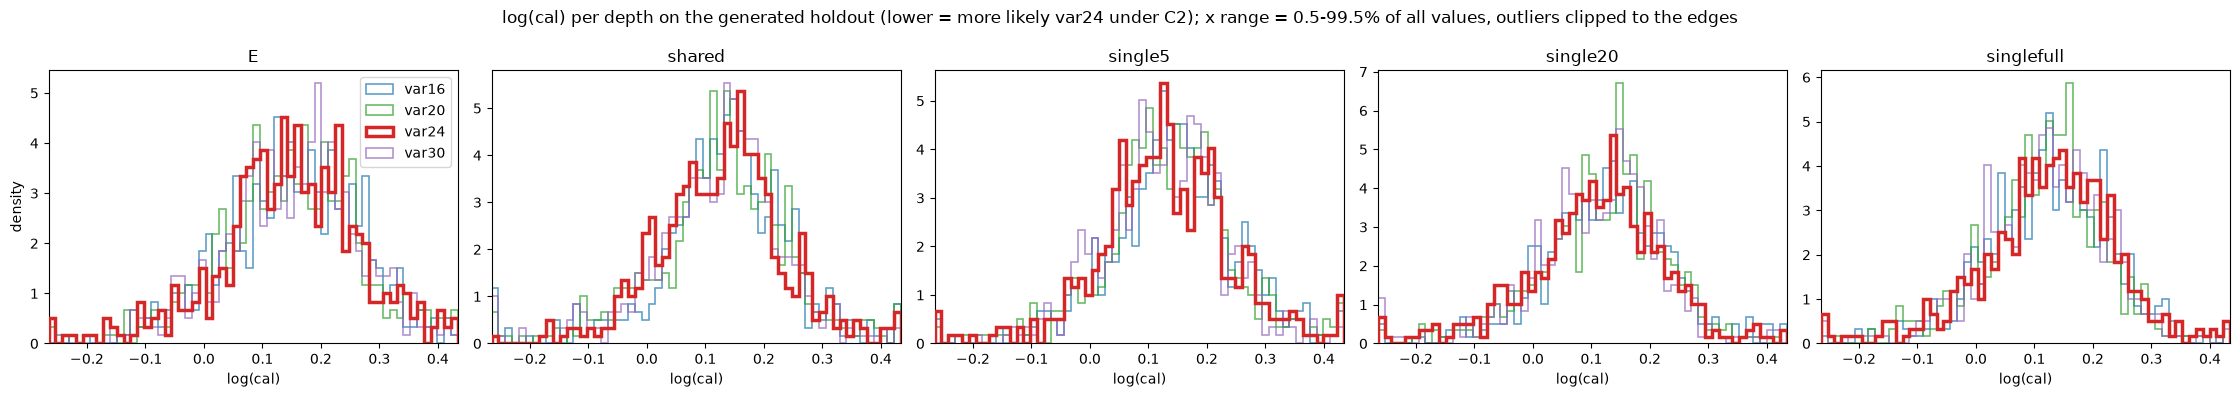

In [5]:
# Distribution of log(cal) per depth under each inverse; var24 highlighted. Shared x-axis across panels.
logcal = np.log(wide["cal"])
x_lo, x_hi = np.percentile(logcal.to_numpy(), [0.5, 99.5])  # common range over all panels
bins = np.linspace(x_lo, x_hi, 61)
colors = {"var16": "tab:blue", "var20": "tab:green", "var24": "tab:red", "var30": "tab:purple"}

fig, axes = plt.subplots(1, len(INVERSES), figsize=(4.5 * len(INVERSES), 4), sharex=True)
for ax, inv in zip(axes, INVERSES):
    for d in DEPTHS:
        x = np.clip(logcal[inv].to_numpy()[labels == d], x_lo, x_hi)  # outliers land in the edge bins
        hl = d == TARGET
        ax.hist(x, bins=bins, density=True, histtype="step", color=colors[d], lw=2.5 if hl else 1.2,
                alpha=1.0 if hl else 0.7, label=d, zorder=3 if hl else 2)
    ax.set_title(inv)
    ax.set_xlabel("log(cal)")
    ax.set_xlim(x_lo, x_hi)
axes[0].set_ylabel("density")
axes[0].legend()
fig.suptitle("log(cal) per depth on the generated holdout (lower = more likely var24 under C2); "
             "x range = 0.5-99.5% of all values, outliers clipped to the edges")
fig.tight_layout()
fig.savefig(OUT / "log_cal_by_depth.png", dpi=150)
plt.show()

In [6]:
# Pre-registered criteria. Pass uses the point estimate; CIs are reported alongside.
# C1 values come from the paired comparison above, the AUCs and their CIs from the separation table; the AUC
# differences (single - shared) get their own paired bootstrap (same resampled images for both inverses).
rng = np.random.default_rng(SEED)
pv = sep.set_index(["inverse", "score", "pair"])
rows = []
for single in ["single5", "single20", "singlefull"]:
    role = ROLE[single]
    c1 = paired[paired.comparison == f"{single} vs shared"].set_index("quantity")
    a = c1[c1.index.str.startswith("inv_mse")].iloc[0]
    b = c1[c1.index.str.startswith("tok_recovery")].iloc[0]
    comp = [("C1", f"{TARGET}: inv_mse reduction 1 - mean_{single} / mean_shared", a.value, 0.10, a.ci_lo, a.ci_hi),
            ("C1", f"{TARGET}: tok_recovery {single} - shared (points)", b.value, 3.0, b.ci_lo, b.ci_hi)]
    for other in ["var20", "var30"]:
        pair = f"{TARGET} vs {other}"
        s_auc, h_auc = pv.loc[(single, "cal", pair)], pv.loc[("shared", "cal", pair)]
        comp.append(("C2", f"AUC(-cal) {pair}, {single}", s_auc.auc, 0.75, s_auc.auc_lo, s_auc.auc_hi))
        vs, vh = -wide["cal"][single].to_numpy(), -wide["cal"]["shared"].to_numpy()
        ps, ns, ph, nh = vs[labels == TARGET], vs[labels == other], vh[labels == TARGET], vh[labels == other]
        lo, hi = boot_ci(lambda i, j: auc(ps[i], ns[j]) - auc(ph[i], nh[j]), [len(ps), len(ns)], rng)
        comp.append(("C2", f"AUC(-cal) {pair}, {single} - shared", s_auc.auc - h_auc.auc, 0.10, lo, hi))
    for crit, quantity, value, thr, lo, hi in comp:
        rows.append({"inverse": single, "role": role, "criterion": crit, "quantity": quantity, "value": value,
                     "threshold": thr, "ci_lo": lo, "ci_hi": hi, "pass": bool(value >= thr)})
    part = pd.DataFrame(rows[-len(comp):])
    rows.append({"inverse": single, "role": role, "criterion": "C1", "quantity": "C1: either component passes",
                 "pass": bool(part[part.criterion == "C1"]["pass"].any())})
    rows.append({"inverse": single, "role": role, "criterion": "C2", "quantity": "C2: all four components pass",
                 "pass": bool(part[part.criterion == "C2"]["pass"].all())})
criteria = pd.DataFrame(rows)
criteria.to_csv(OUT / "criteria.csv", index=False)
with pd.option_context("display.float_format", "{:.4g}".format, "display.max_colwidth", None):
    display(criteria)

,inverse,role,criterion,quantity,value,threshold,ci_lo,ci_hi,pass
0,single5,primary,C1,var24: inv_mse reduction 1 - mean_single5 / mean_shared,-0.1243,0.1,-0.1267,-0.1219,False
1,single5,primary,C1,var24: tok_recovery single5 - shared (points),-1.266,3,-1.442,-1.112,False
2,single5,primary,C2,"AUC(-cal) var24 vs var20, single5",0.5189,0.75,0.4842,0.5577,False
3,single5,primary,C2,"AUC(-cal) var24 vs var20, single5 - shared",0.01351,0.1,-0.03065,0.05453,False
4,single5,primary,C2,"AUC(-cal) var24 vs var30, single5",0.4925,0.75,0.4587,0.5291,False
5,single5,primary,C2,"AUC(-cal) var24 vs var30, single5 - shared",-0.00985,0.1,-0.0525,0.03419,False
6,single5,primary,C1,C1: either component passes,NaN,NaN,NaN,NaN,False
7,single5,primary,C2,C2: all four components pass,NaN,NaN,NaN,NaN,False
8,single20,secondary,C1,var24: inv_mse reduction 1 - mean_single20 / mean_shared,-0.04224,0.1,-0.04299,-0.04144,False
9,single20,secondary,C1,var24: tok_recovery single20 - shared (points),-0.3188,3,-0.48,-0.156,False


In [7]:
# Summary: all inverses side by side. Training size from each checkpoint's config.json and the shards of its --data
# (as finetune_inverse.py selects them); var24 means and AUCs (score = -cal) with the 95% CIs computed above.
def training(inv):
    """(models, training images, epochs, optimizer steps) of one inverse; E is not trained."""
    ckpt = cfg["inverses"][inv]["ckpt"]
    if ckpt is None:
        return "-", 0, 0, 0
    c = json.loads((Path(ckpt).parent / "config.json").read_text())
    n_train = 0
    for d in sorted((Path(c["data"]) / "var").iterdir()):
        if not d.is_dir() or (c.get("models") and d.name not in c["models"]):  # no "models" key = all depths
            continue
        n = sum(len(np.load(p)["classes"]) for p in d.glob("shard_*.npz"))
        n = n if c["max_per_model"] is None else min(n, c["max_per_model"])
        assert n > c["holdout_per_model"], f"{d}: {n} rows"
        n_train += n - c["holdout_per_model"]
    models = "+".join(c["models"]) if c.get("models") else "all 4 depths"
    return models, n_train, c["epochs"], c["epochs"] * -(-n_train // c["batch_size"])  # one pass in batches per epoch


def fmt(v, lo, hi, f="{:.4g}"):
    return f"{f.format(v)} [{f.format(lo)}, {f.format(hi)}]"


rows = []
for inv in INVERSES:
    models, n_train, epochs, steps = training(inv)
    m = means[(means.depth == TARGET) & (means.inverse == inv)].set_index("metric")
    row = {"inverse": inv, "role": ROLE[inv], "trained on": models, "training images": n_train, "epochs": epochs,
           "optimizer steps": steps}
    for metric in ["inv_mse", "tok_recovery"]:
        r = m.loc[metric]
        row.update({f"{TARGET} {metric}": r["mean"], f"{TARGET} {metric} lo": r.ci_lo, f"{TARGET} {metric} hi": r.ci_hi})
    for other in ["var20", "var30"]:
        a = sep.set_index(["inverse", "score", "pair"]).loc[(inv, "cal", f"{TARGET} vs {other}")]
        row.update({f"AUC(-cal) vs {other}": a.auc, f"AUC(-cal) vs {other} lo": a.auc_lo,
                    f"AUC(-cal) vs {other} hi": a.auc_hi})
    rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "summary.csv", index=False)

shown = summary[["inverse", "role", "trained on", "training images", "epochs", "optimizer steps"]].copy()
for col, f in [(f"{TARGET} inv_mse", "{:.4g}"), (f"{TARGET} tok_recovery", "{:.4f}"),
               ("AUC(-cal) vs var20", "{:.3f}"), ("AUC(-cal) vs var30", "{:.3f}")]:
    shown[f"{col} [95% CI]"] = [fmt(v, lo, hi, f) for v, lo, hi in zip(summary[col], summary[f"{col} lo"],
                                                                         summary[f"{col} hi"])]
with pd.option_context("display.max_colwidth", None):
    display(shown)

print("singlefull: C1 / C2 against the thresholds - EXPLORATORY (added after the criteria were fixed; "
      "pass/fail is decided on single5 only)")
with pd.option_context("display.float_format", "{:.4g}".format, "display.max_colwidth", None):
    display(criteria[criteria.inverse == "singlefull"])

,inverse,role,trained on,training images,epochs,optimizer steps,var24 inv_mse [95% CI],var24 tok_recovery [95% CI],AUC(-cal) vs var20 [95% CI],AUC(-cal) vs var30 [95% CI]
0,E,control,-,0,0,0,"0.1877 [0.1789, 0.1965]","0.2641 [0.2591, 0.2702]","0.499 [0.465, 0.536]","0.507 [0.471, 0.546]"
1,shared,control,all 4 depths,9840,5,3075,"0.03955 [0.03862, 0.04048]","0.2726 [0.2689, 0.2767]","0.505 [0.470, 0.542]","0.502 [0.467, 0.536]"
2,single5,primary,var24,2460,5,770,"0.04446 [0.04353, 0.04543]","0.2599 [0.2561, 0.2641]","0.519 [0.484, 0.558]","0.493 [0.459, 0.529]"
3,single20,secondary,var24,2460,20,3080,"0.04122 [0.04028, 0.04217]","0.2694 [0.2656, 0.2736]","0.534 [0.500, 0.569]","0.508 [0.472, 0.541]"
4,singlefull,exploratory,var24,9840,5,3075,"0.03964 [0.03872, 0.04056]","0.2721 [0.2683, 0.2760]","0.472 [0.436, 0.505]","0.477 [0.442, 0.514]"


singlefull: C1 / C2 against the thresholds - EXPLORATORY (added after the criteria were fixed; pass/fail is decided on single5 only)


,inverse,role,criterion,quantity,value,threshold,ci_lo,ci_hi,pass
16,singlefull,exploratory,C1,var24: inv_mse reduction 1 - mean_singlefull / mean_shared,-0.002297,0.1,-0.00273,-0.001806,False
17,singlefull,exploratory,C1,var24: tok_recovery singlefull - shared (points),-0.04969,3,-0.2065,0.1069,False
18,singlefull,exploratory,C2,"AUC(-cal) var24 vs var20, singlefull",0.4716,0.75,0.4365,0.5048,False
19,singlefull,exploratory,C2,"AUC(-cal) var24 vs var20, singlefull - shared",-0.03377,0.1,-0.0794,0.01111,False
20,singlefull,exploratory,C2,"AUC(-cal) var24 vs var30, singlefull",0.477,0.75,0.442,0.5136,False
21,singlefull,exploratory,C2,"AUC(-cal) var24 vs var30, singlefull - shared",-0.02535,0.1,-0.0691,0.01689,False
22,singlefull,exploratory,C1,C1: either component passes,NaN,NaN,NaN,NaN,False
23,singlefull,exploratory,C2,C2: all four components pass,NaN,NaN,NaN,NaN,False


## Findings
